# Learned partitions for black-box optimization: a 5-minute demo

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/raja-sunkara/Learned-Partitions-SequOOL/blob/main/notebooks/demo.ipynb)

Companion to **Adaptive Partitioning Schemes for Optimistic Optimization** (Sunkara & Tripathy, ICML 2025):
[paper](https://proceedings.mlr.press/v267/sunkara25a.html) · [arXiv](https://arxiv.org/abs/2610.04039) · [code](https://github.com/raja-sunkara/Learned-Partitions-SequOOL)

**The idea.** Partition-based optimizers such as SequOOL search by repeatedly splitting the domain into boxes along the coordinate axes. If a 20-dimensional function really depends on only 2 hidden directions, most of those splits are wasted.
We spend a small part of the budget *learning* those directions, then run SequOOL on partitions built in that 2-D subspace.

This notebook runs both on the same problem and the same budget. It takes about a minute on a CPU.

In [1]:
%pip install -q "git+https://github.com/raja-sunkara/Learned-Partitions-SequOOL.git#subdirectory=package" matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. A 20-D function with a 2-D active subspace

We hide a 2-D function inside 20 dimensions with a random rotation: $f(x) = g(Ax - z^\star)$, where $A$ is a random $2 \times 20$ matrix with orthonormal rows and $g(z) = |z_1|^{1.5} + |z_2|^{1.5}$, a bowl with a sharp, non-differentiable bottom. The optimizer only gets to call `f`; it never sees $A$. The minimum value is 0.

In [2]:
import numpy as np
from learned_partitions import minimize

D, M = 20, 2          # ambient and hidden dimension
BUDGET = 2000         # evaluations of f, for each method
SEEDS = range(5)      # a fresh random rotation per seed

def make_problem(seed):
    rng = np.random.default_rng(seed)
    A = np.linalg.qr(rng.standard_normal((D, D)))[0][:M]   # hidden directions
    z_star = A @ rng.uniform(-0.6, 0.6, D)                   # optimum lies inside the box
    def f(x):
        return float(np.sum(np.abs(A @ x - z_star) ** 1.5))
    return f, A, z_star

bounds = [(-1.0, 1.0)] * D

## 2. Run plain SequOOL and SequOOL on a learned partition

`minimize` is one call. `method="sequool"` is the baseline with axis-aligned splits; the default `method="learned"` first estimates the active subspace (here with about 210 finite-difference evaluations), then searches it. Both get exactly the same budget. We also record every point each method evaluates.

In [3]:
from scipy.linalg import subspace_angles

runs = {"SequOOL": [], "Learned partition": []}
points = {}
for seed in SEEDS:
    f, A, _ = make_problem(seed)
    for name, kwargs in [("SequOOL", {"method": "sequool"}), ("Learned partition", {})]:
        seen = []
        res = minimize(lambda x: seen.append(x.copy()) or f(x), bounds, budget=BUDGET, seed=seed, **kwargs)
        runs[name].append(res)
        if seed == 0:
            points[name] = (np.array(seen), A)

for name, results in runs.items():
    finals = [r.fun for r in results]
    print(f"{name:18s} best f (median over {len(finals)} seeds): {np.median(finals):.1e}   evaluations used: {results[0].nfev}")

angles = [np.rad2deg(subspace_angles(r.directions.T, make_problem(s)[1].T)).max()
          for s, r in zip(SEEDS, runs["Learned partition"])]
print("Learned subspace dimension:", {r.m for r in runs["Learned partition"]},
      "| largest angle to the true subspace:", f"{max(angles):.2g} degrees")

SequOOL            best f (median over 5 seeds): 9.7e-12   evaluations used: 1995
Learned partition  best f (median over 5 seeds): 8.5e-25   evaluations used: 1995
Learned subspace dimension: {2} | largest angle to the true subspace: 0.0016 degrees


## 3. Regret versus evaluations

Regret is $f(\text{best point so far}) - f^\star$. Lines show the median over seeds; the band spans the best and worst seed. Values below $10^{-30}$, including exact zeros, are drawn at the bottom of the axis.

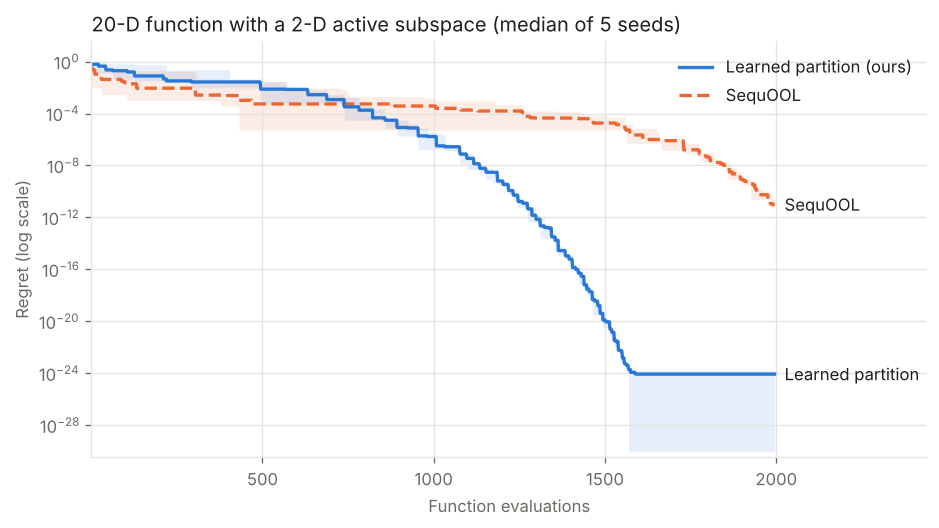

In [4]:
import matplotlib.pyplot as plt

STYLE = {"Learned partition": dict(color="#2a78d6", ls="-"),   # blue, solid
         "SequOOL":           dict(color="#eb6834", ls="--")}  # orange, dashed
FLOOR = 1e-30
INK, MUTED, GRID = "#1f1f1e", "#6b6a64", "#e4e3df"

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=120)
for name in ["SequOOL", "Learned partition"]:
    curves = np.array([np.maximum(r.history, FLOOR) for r in runs[name]])
    n = np.arange(1, curves.shape[1] + 1)
    med = np.median(curves, axis=0)
    ax.fill_between(n, curves.min(axis=0), curves.max(axis=0), color=STYLE[name]["color"], alpha=0.12, lw=0)
    ax.plot(n, med, lw=2, **STYLE[name])
    ax.annotate(name, (n[-1], med[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", color=INK, fontsize=10)

ax.set_yscale("log")
ax.set_ylim(FLOOR / 3, None)
ax.set_xlim(1, BUDGET * 1.22)
ax.set_xlabel("Function evaluations", color=MUTED)
ax.set_ylabel("Regret (log scale)", color=MUTED)
ax.set_title("20-D function with a 2-D active subspace (median of 5 seeds)", color=INK, loc="left")
ax.grid(True, which="major", color=GRID, lw=0.8)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
for s in ["left", "bottom"]:
    ax.spines[s].set_color(GRID)
ax.tick_params(colors=MUTED)
ax.legend([plt.Line2D([], [], lw=2, **STYLE[k]) for k in ["Learned partition", "SequOOL"]],
          ["Learned partition (ours)", "SequOOL"], frameon=False, loc="upper right", labelcolor=INK)
plt.tight_layout()
plt.show()

For the first several hundred evaluations the learned method is behind: about 210 evaluations go into estimating the subspace, and its search starts from the whole projected domain. Once SequOOL is splitting in the 2-D subspace the function actually depends on, every split counts, and regret falls far faster than with axis-aligned splits across all 20 dimensions.

## 4. Where each method spends its evaluations

Each evaluated point, projected onto the true 2-D subspace (seed 0). The background shows $g$, and the star is the optimum.

SequOOL's points land in a small blob: each axis-aligned split moves $x$ mostly along the 18 directions $f$ ignores, so it barely changes $Ax$, the only thing that matters. Here the blob happens to contain the optimum, so SequOOL still converges, just slowly. The learned method searches the whole projected domain coarse-to-fine and then zooms into the optimum, so every evaluation moves it in a direction that changes $f$.

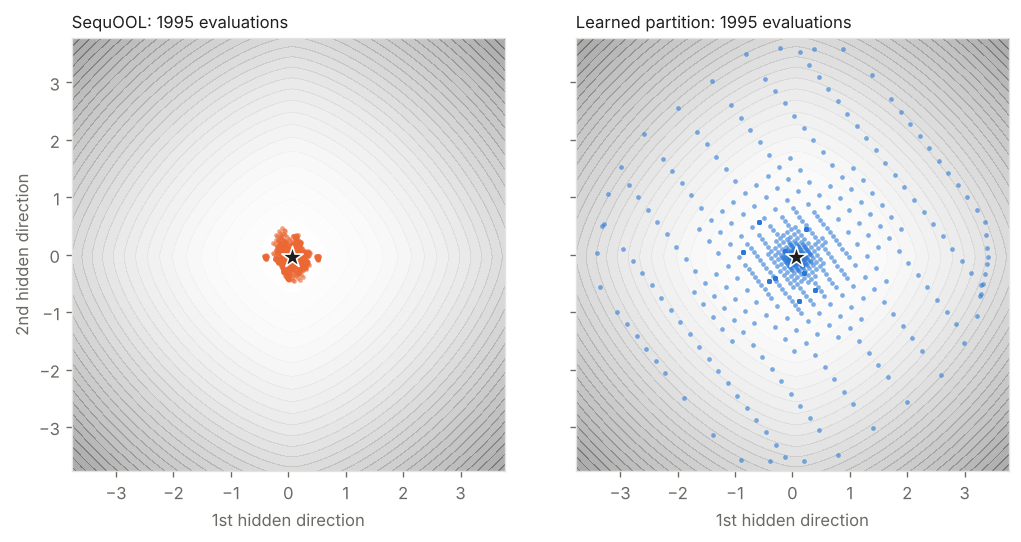

In [5]:
f0, A0, z_star0 = make_problem(0)
proj = {k: v[0] @ A0.T for k, v in points.items()}
lim = 1.05 * max(np.abs(p).max() for p in proj.values())

g = np.linspace(-lim, lim, 300)
Z1, Z2 = np.meshgrid(g, g)
G = np.sum(np.abs(np.stack([Z1, Z2], -1) - z_star0) ** 1.5, axis=-1)

fig, axes = plt.subplots(1, 2, figsize=(9, 4.4), dpi=120, sharex=True, sharey=True)
for ax, name in zip(axes, ["SequOOL", "Learned partition"]):
    ax.contourf(Z1, Z2, G, levels=30, cmap="Greys", alpha=0.35)
    ax.scatter(*proj[name].T, s=8, color=STYLE[name]["color"], alpha=0.6, lw=0)
    ax.scatter(*z_star0, marker="*", s=180, color=INK, edgecolor="white", lw=1, zorder=3)
    ax.set_title(f"{name}: {len(proj[name])} evaluations", color=INK, fontsize=10, loc="left")
    ax.set_aspect("equal")
    ax.tick_params(colors=MUTED)
    for s in ax.spines.values():
        s.set_color(GRID)
axes[0].set_ylabel("2nd hidden direction", color=MUTED)
for ax in axes:
    ax.set_xlabel("1st hidden direction", color=MUTED)
plt.tight_layout()
plt.show()

## 5. When does it help? An honest check

The learned partition shines when the function is smooth enough that refining around the best cell keeps paying off. It is not a free win everywhere. The cell below runs both methods on four hidden 2-D functions over 5 random rotations each, with the same budget.

In [6]:
TESTS = {
    "Sharp bowl  |z|^1.5":     lambda z: np.sum(np.abs(z) ** 1.5),
    "Sphere":                  lambda z: np.sum(z ** 2),
    "Rastrigin (many minima)": lambda z: 10 * M + np.sum((3 * z) ** 2 - 10 * np.cos(2 * np.pi * 3 * z)),
    "Rosenbrock (curved valley)": lambda z: 100 * ((z[1] + 1) - (z[0] + 1) ** 2) ** 2 + z[0] ** 2,
}
print(f"{'function':28s} {'SequOOL median':>15s} {'learned median':>15s}   learned better")
for name, g in TESTS.items():
    base, ours = [], []
    for seed in range(5):
        rng = np.random.default_rng(seed)
        A = np.linalg.qr(rng.standard_normal((D, D)))[0][:M]
        z_star = A @ rng.uniform(-0.6, 0.6, D)
        f = lambda x: float(g(A @ x - z_star))
        base.append(minimize(f, bounds, budget=BUDGET, method="sequool").fun)
        ours.append(minimize(f, bounds, budget=BUDGET, seed=seed).fun)
    base, ours = np.array(base), np.array(ours)
    print(f"{name:28s} {np.median(base):15.1e} {np.median(ours):15.1e}   {np.sum(ours < base)}/5")

function                      SequOOL median  learned median   learned better


Sharp bowl  |z|^1.5                  9.7e-12         8.5e-25   5/5


Sphere                               1.0e-15         3.1e-33   5/5


Rastrigin (many minima)              3.0e-12         9.9e-01   1/5


Rosenbrock (curved valley)           1.7e-05         9.9e-06   2/5


With these seeds: on the two smooth bowls the learned partition wins on every rotation, by 13 to 18 orders of magnitude. On Rastrigin it usually loses: it finds the subspace, but SequOOL's greedy splitting in the learned 2-D frame tends to settle in a neighboring local minimum (value about 0.99), while plain SequOOL in 20-D, where the minimizers form an 18-dimensional plane, hits the global one. On Rosenbrock's curved valley the two are close and the winner depends on the rotation. So learning the partition pays off most when the hidden function is fairly well-behaved near its optimum.

## 6. Try it on your own function

Any Python function of a 1-D numpy array works. Swap in your simulator, hyperparameter objective, or design problem:

In [7]:
def my_objective(x):
    # replace with your expensive black-box function
    return float(np.sum((x[:3] - 0.25) ** 2) + 0.1 * np.sin(5 * x[3]))

res = minimize(my_objective, bounds=[(-1, 1)] * 30, budget=600)
print("best value:", res.fun)
print("learned subspace dimension:", res.m)
print("best point (first 5 coords):", np.round(res.x[:5], 3))

best value: -0.01938959204564921
learned subspace dimension: 3
best point (first 5 coords): [ 0.263  0.294  0.226 -0.044  0.   ]


Useful options: `budget`, `m` (fix the subspace dimension), `subspace="nn"` (neural-network estimator, for noisy or non-smooth objectives; needs PyTorch), and `maximize` for maximization. See the [package README](https://github.com/raja-sunkara/Learned-Partitions-SequOOL/tree/main/package) for details.

## Citation

```bibtex
@InProceedings{pmlr-v267-sunkara25a,
  title     = {Adaptive Partitioning Schemes for Optimistic Optimization},
  author    = {Sunkara, Raja and Tripathy, Ardhendu},
  booktitle = {Proceedings of the 42nd International Conference on Machine Learning},
  pages     = {58029--58064},
  year      = {2025},
  volume    = {267},
  series    = {Proceedings of Machine Learning Research},
  publisher = {PMLR},
  url       = {https://proceedings.mlr.press/v267/sunkara25a.html}
}
```